In [1]:
%pip install -U huggingface_hub

   ---------------------------------------- 0.0/855.2 kB ? eta -:--:--
   --------------------------------------- 855.2/855.2 kB 12.6 MB/s eta 0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 2.2.0
    Uninstalling huggingface_hub-2.2.0:
      Successfully uninstalled huggingface_hub-2.2.0
Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tokenizers 0.23.1 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.3.0 which is incompatible.
transformers 5.16.1 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 2.3.0 which is incompatible.

[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
## Get data set (Takes FOREVER)

from huggingface_hub import snapshot_download

dataset_path = snapshot_download(repo_id="JackFurby/blackjack", repo_type="dataset", local_dir="./data/blackjack")

KeyboardInterrupt: 

In [ ]:
##Data path

from pathlib import Path

data_folder = Path(r"C:\Users\hartmawa\Music\Deep Learning\src\Project\data\blackjack")


Number of training hands: 14304
Sample annotation:
{'img_path': 'imgs/standard/train/0/0.png', 'class_label': 1, 'concept_label': [1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0], 'player_card_points': [[[[172, 974], [50, 974], [172, 789], [50, 789]], 'AD'], [[[185, 789], [307, 789], [185, 973], [307, 973]], 'KS']], 'dealer_card_points': [[[[50, 50], [172, 50], [50, 235], [172, 235]], '7D']], 'game_number': 0}


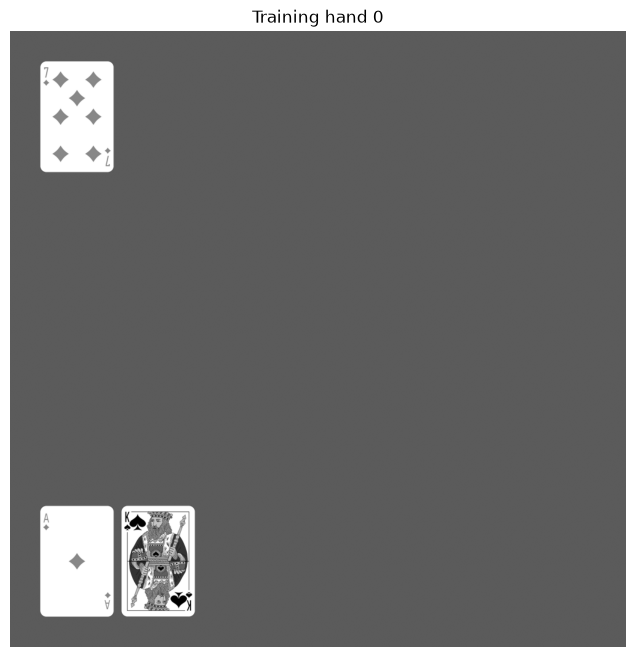

In [ ]:
## Select training example to see how everyhtign is working

import json
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

data_folder = Path("./data/blackjack")

# Read the training annotations
with open(data_folder / "splits/standard/train.json", "r") as file: train_annotations = json.load(file)

print("Number of training hands:", len(train_annotations))

# Get the first hand
sample_id = next(iter(train_annotations))
sample = train_annotations[sample_id]

print("Sample annotation:")
print(sample)

# Open and display the full image
image = Image.open(data_folder / sample["img_path"]).convert("L")


plt.figure(figsize=(8, 8))
plt.imshow(image, cmap="gray")
plt.title(f"Training hand {sample_id}")
plt.axis("off")
plt.show()

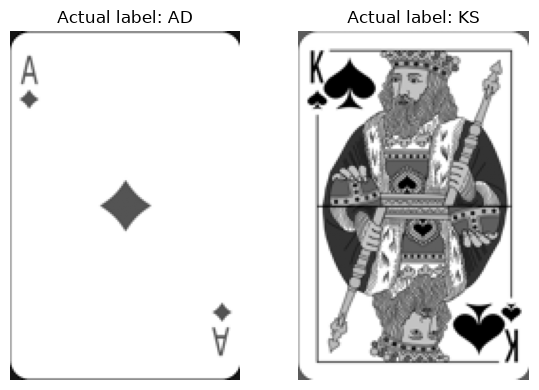

In [ ]:
## Crop Just Player Cards so we can identify individual cards (figure out something later for whole hand)

player_cards = sample["player_card_points"]

fig, axes = plt.subplots(1, len(player_cards),figsize=(3 * len(player_cards), 4), squeeze=False)

for ax, (corners, card_label) in zip(axes[0], player_cards):
    # Find the rectangle enclosing the four corners
    x_coordinates = [point[0] for point in corners]
    y_coordinates = [point[1] for point in corners]

    crop_box = (min(x_coordinates),min(y_coordinates),max(x_coordinates),max(y_coordinates))

    card_image = image.crop(crop_box) #Crop image

    ax.imshow(card_image, cmap="gray")
    ax.set_title(f"Actual label: {card_label}")
    ax.axis("off")

#plot image to make sure crop worked
plt.tight_layout()
plt.show()

In [3]:
## Import ResNet-18

import json
import torch
from pathlib import Path
from PIL import Image
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

torch.manual_seed(42)

data_folder = Path("./data/blackjack")
ranks = ["A", "2", "3", "4", "5", "6", "7",
         "8", "9", "10"] #Only have 10 instead of face cards since they are all 10


# Normalize using the pretrained model's ImageNet settings.
transform = transforms.Compose([
    transforms.Resize((224, 224)), #Make sqaure and consistent size for everything
    transforms.Grayscale(num_output_channels=3),#Resnet needs 3 chanesl
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


class CardDataset(Dataset):
    def __init__(self, root, split, transform):
        self.root = root
        self.transform = transform
        self.cards = []

        with open(root / f"splits/standard/{split}.json") as f:
            annotations = json.load(f)

        for sample in annotations.values():
            for group in ["player_card_points", "dealer_card_points"]:
                for corners, card_label in sample[group]:
                    # Remove suit
                    rank = card_label[:-1]
                    
                    #combine face cards
                    if rank in ["10","J","Q","K"]:
                        rank="10" #assign all to 10


                    xs = [point[0] for point in corners]
                    ys = [point[1] for point in corners]
                    box = (min(xs), min(ys), max(xs), max(ys))

                    self.cards.append((sample["img_path"],box,ranks.index(rank)))

    def __len__(self):
        return len(self.cards)

    def __getitem__(self, index):
        image_path, box, label = self.cards[index]

        with Image.open(self.root / image_path) as image:
            card = image.convert("RGB").crop(box)

        return self.transform(card), label


train_dataset = CardDataset(data_folder, "train", transform)
val_dataset = CardDataset(data_folder, "val", transform)

# num_workers=0 keeps this simple for a Windows notebook.
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=0)


In [ ]:
device = torch.device("cuda")

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze the pretrained parameters.
for parameter in model.parameters():
    parameter.requires_grad = False

#Make new output layer with the 10 featuers
model.fc = nn.Linear(model.fc.in_features, len(ranks))
model = model.to(device)

#set loss and optimization
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)

Using: cuda


In [ ]:
## Train Model

num_epochs = 3

for epoch in range(num_epochs):
    model.eval()
    model.fc.train()

    #Initialize counters at zero
    total_loss = 0
    train_correct = 0
    train_total = 0

    for batch_index, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_total += labels.size(0)

        if (batch_index + 1) % 100 == 0:
            print(
                f"Epoch {epoch + 1}: "
                f"batch {batch_index + 1}/{len(train_loader)}"
            )

    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += labels.size(0)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Loss: {total_loss / train_total:.4f} | "
        f"Train accuracy: {100 * train_correct / train_total:.1f}% | "
        f"Validation accuracy: {100 * val_correct / val_total:.1f}%"
    )

Epoch 1: batch 100/1876
Epoch 1: batch 200/1876
Epoch 1: batch 300/1876
Epoch 1: batch 400/1876
Epoch 1: batch 500/1876
Epoch 1: batch 600/1876
Epoch 1: batch 700/1876
Epoch 1: batch 800/1876
Epoch 1: batch 900/1876
Epoch 1: batch 1000/1876
Epoch 1: batch 1100/1876
Epoch 1: batch 1200/1876
Epoch 1: batch 1300/1876
Epoch 1: batch 1400/1876
Epoch 1: batch 1500/1876
Epoch 1: batch 1600/1876
Epoch 1: batch 1700/1876
Epoch 1: batch 1800/1876
Epoch 1/3 | Loss: 0.1660 | Train accuracy: 98.1% | Validation accuracy: 100.0%
Epoch 2: batch 100/1876
Epoch 2: batch 200/1876
Epoch 2: batch 300/1876
Epoch 2: batch 400/1876
Epoch 2: batch 500/1876
Epoch 2: batch 600/1876
Epoch 2: batch 700/1876
Epoch 2: batch 800/1876
Epoch 2: batch 900/1876
Epoch 2: batch 1000/1876
Epoch 2: batch 1100/1876
Epoch 2: batch 1200/1876
Epoch 2: batch 1300/1876
Epoch 2: batch 1400/1876
Epoch 2: batch 1500/1876
Epoch 2: batch 1600/1876
Epoch 2: batch 1700/1876
Epoch 2: batch 1800/1876
Epoch 2/3 | Loss: 0.0103 | Train accura

In [ ]:
## Save Model

from pathlib import Path

model_name="resnet18_grayscale_combinedface"

save_path = Path.home() / "models" / f"{model_name}.pth"
save_path.parent.mkdir(parents=True, exist_ok=True)

torch.save({ "model_state_dict": model.state_dict(),"ranks": ranks, "model_name": model_name}, save_path)




Model saved to: C:\Users\hartmawa\models\resnet18_grayscale_combinedface.pth


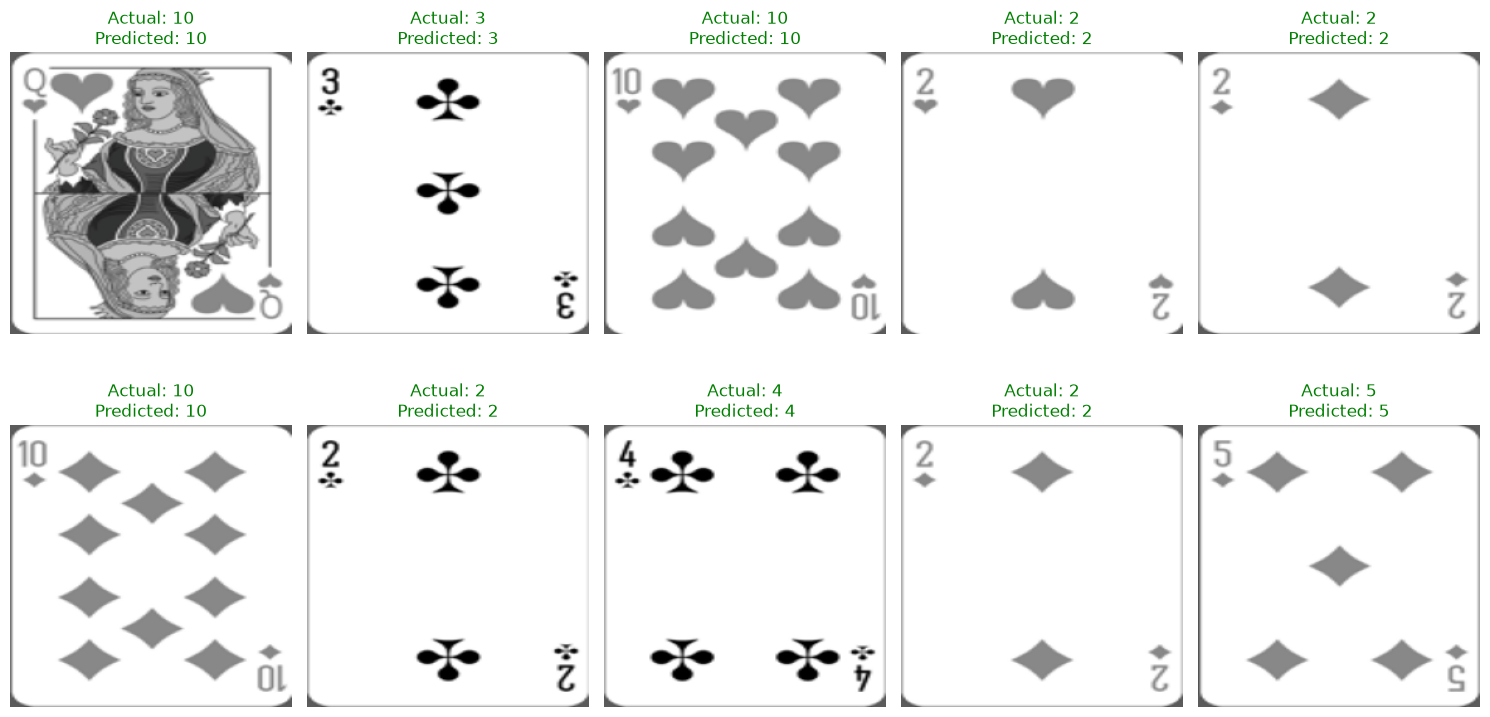

In [ ]:
import random
import torch
import matplotlib.pyplot as plt

indices = random.sample(range(len(val_dataset)), k=min(10, len(val_dataset)))

mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]

fig, axes = plt.subplots(2, 5, figsize=(15, 8))

for ax in axes.flat:
    ax.axis("off")

model.eval()
with torch.no_grad():
    for ax, index in zip(axes.flat, indices):
        card_tensor, actual_label = val_dataset[index]
        actual_label = int(actual_label)

        scores = model(card_tensor.unsqueeze(0).to(device))
        predicted_label = scores.argmax(dim=1).item()

        # Undo normalization for display.
        display_card = (card_tensor.cpu() * std + mean).clamp(0, 1)

        ax.imshow(display_card.permute(1, 2, 0))
        ax.set_title(f"Actual: {ranks[actual_label]}\n" f"Predicted: {ranks[predicted_label]}",color="green" if predicted_label == actual_label else "red")

plt.tight_layout()
plt.show()

In [10]:
## Load in Real Photos of Cards

from PIL import Image, ImageOps

folder = Path(r"C:\Users\hartmawa\Music\Deep Learning\src\Project\Full_Deck_BW")

image_paths=sorted(path for path in folder.iterdir())

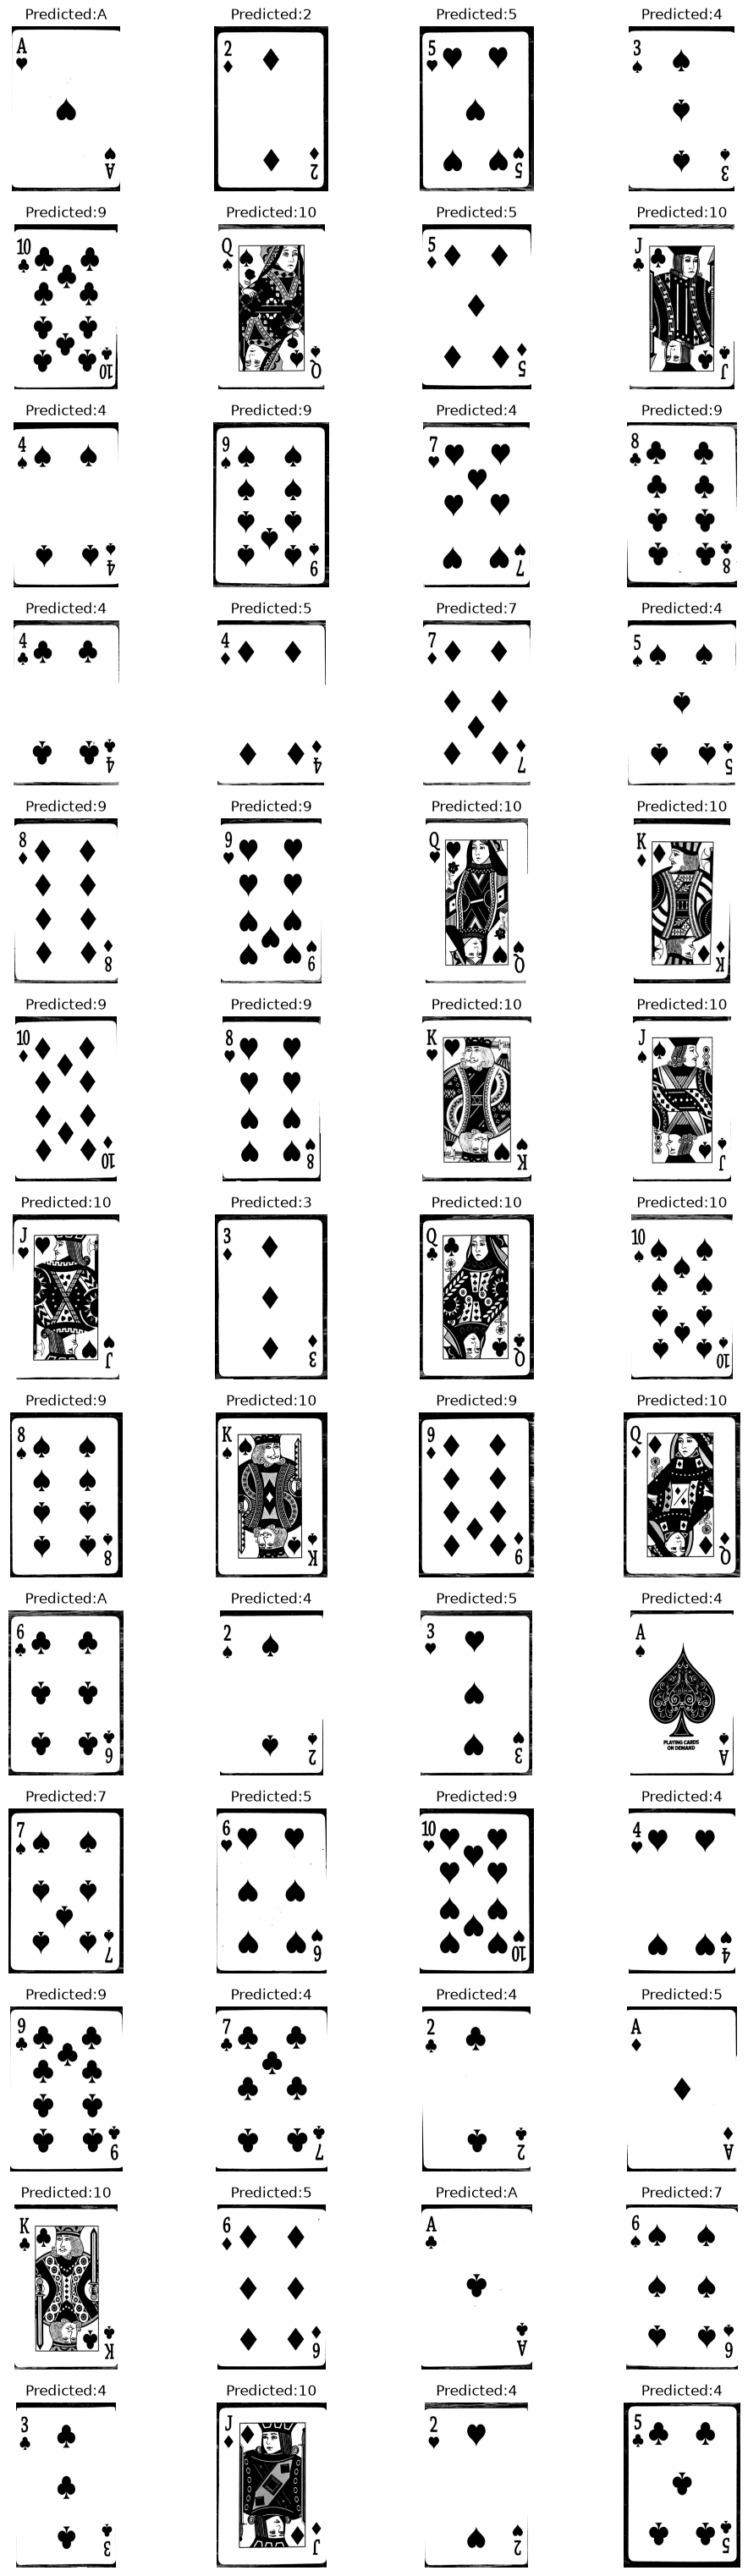

In [ ]:
## Open Model and avaluate Pictures

model.eval() #Put model in evaluation mode

fig, axes = plt.subplots(13,4, figsize=(12,39))

for ax in axes.flat:
    ax.axis("off")

with torch.no_grad():
    for ax, path in zip(axes.flat, image_paths):
        image=ImageOps.exif_transpose(Image.open(path).convert("RGB")) #Make sure image is in RGB
        
        inputs=transform(image).unsqueeze(0).to(device) #Prepare image
        
        scores=model(inputs)#Run Model
        prediction=scores.argmax(dim=1).item()
        
        ax.imshow(image)
        ax.set_title(f"Predicted:{ranks[prediction]}") #Ideally come back latter when iamges actually have lable so I dont have to go through and manually count
        
plt.show()